# Customer Churn Analysis
Which customers are leaving a telecom company, why, and can we predict it?

**Dataset:** Telco Customer Churn (7,043 customers). **Tools:** Python, SQL (SQLite), Pandas, Seaborn, Scikit-learn.

Run the cells from top to bottom (Shift + Enter on each cell).

### Imports

In [1]:
import os
import sqlite3
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # makes results identical every time you run

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
DATA_FILE = os.path.join(HERE, "data", "telco_churn.csv")
OUT = os.path.join(HERE, "outputs")
CHARTS = os.path.join(OUT, "charts")
os.makedirs(CHARTS, exist_ok=True)

summary = []  # lines we will write into outputs/summary.md


def say(text=""):
    print(text)
    summary.append(text)

### STEP 1 - Load

In [2]:
say("# Churn Analysis - Results Summary\n")
df = pd.read_csv(DATA_FILE)
say(f"- Rows (customers): **{df.shape[0]:,}**, Columns: **{df.shape[1]}**")

# Churn Analysis - Results Summary

- Rows (customers): **7,043**, Columns: **21**


### STEP 2 - Clean

In [3]:
# TotalCharges is text because 11 rows contain a blank space. Those customers
# have tenure = 0 (brand new, never billed), so their total is really 0.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_total = int(df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
duplicates = int(df.duplicated().sum())
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)  # Yes -> 1, No -> 0
churn_rate = df["Churn_flag"].mean() * 100
say(f"- Blank TotalCharges fixed: **{blank_total}** (all new customers, set to 0)")
say(f"- Duplicate rows: **{duplicates}**")
say(f"- Overall churn rate: **{churn_rate:.1f}%** "
    f"({df['Churn_flag'].sum():,} of {len(df):,} customers left)\n")

- Blank TotalCharges fixed: **11** (all new customers, set to 0)
- Duplicate rows: **0**
- Overall churn rate: **26.5%** (1,869 of 7,043 customers left)



### STEP 3 - SQL questions

In [4]:
say("## SQL findings\n")
con = sqlite3.connect(os.path.join(OUT, "churn.db"))
df.drop(columns=["Churn_flag"]).to_sql("customers", con, if_exists="replace", index=False)

queries = {
    "churn_by_contract": """
        SELECT Contract,
               COUNT(*) AS customers,
               SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_rate_pct
        FROM customers
        GROUP BY Contract
        ORDER BY churn_rate_pct DESC;""",
    "churn_by_internet_service": """
        SELECT InternetService,
               COUNT(*) AS customers,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_rate_pct
        FROM customers
        GROUP BY InternetService
        ORDER BY churn_rate_pct DESC;""",
    "churn_by_payment_method": """
        SELECT PaymentMethod,
               COUNT(*) AS customers,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_rate_pct
        FROM customers
        GROUP BY PaymentMethod
        ORDER BY churn_rate_pct DESC;""",
    "churn_by_tenure_group": """
        SELECT CASE WHEN tenure <= 12 THEN '1) 0-12 months'
                    WHEN tenure <= 24 THEN '2) 13-24 months'
                    WHEN tenure <= 48 THEN '3) 25-48 months'
                    ELSE '4) 49+ months' END AS tenure_group,
               COUNT(*) AS customers,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_rate_pct
        FROM customers
        GROUP BY tenure_group
        ORDER BY tenure_group;""",
    "monthly_revenue_lost": """
        SELECT ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 0) AS monthly_revenue_lost,
               ROUND(SUM(MonthlyCharges), 0) AS total_monthly_revenue,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END) / SUM(MonthlyCharges), 1) AS pct_lost
        FROM customers;""",
}
sql_results = {}
for name, q in queries.items():
    result = pd.read_sql_query(q, con)
    sql_results[name] = result
    result.to_csv(os.path.join(OUT, f"sql_{name}.csv"), index=False)
    say(f"**{name.replace('_', ' ').title()}**\n")
    say(result.to_markdown(index=False))
    say()
con.close()

## SQL findings

**Churn By Contract**

| Contract       |   customers |   churned |   churn_rate_pct |
|:---------------|------------:|----------:|-----------------:|
| Month-to-month |        3875 |      1655 |             42.7 |
| One year       |        1473 |       166 |             11.3 |
| Two year       |        1695 |        48 |              2.8 |

**Churn By Internet Service**

| InternetService   |   customers |   churn_rate_pct |
|:------------------|------------:|-----------------:|
| Fiber optic       |        3096 |             41.9 |
| DSL               |        2421 |             19   |
| No                |        1526 |              7.4 |

**Churn By Payment Method**

| PaymentMethod             |   customers |   churn_rate_pct |
|:--------------------------|------------:|-----------------:|
| Electronic check          |        2365 |             45.3 |
| Mailed check              |        1612 |             19.1 |
| Bank transfer (automatic) |        1544 |        

### STEP 4 - Charts

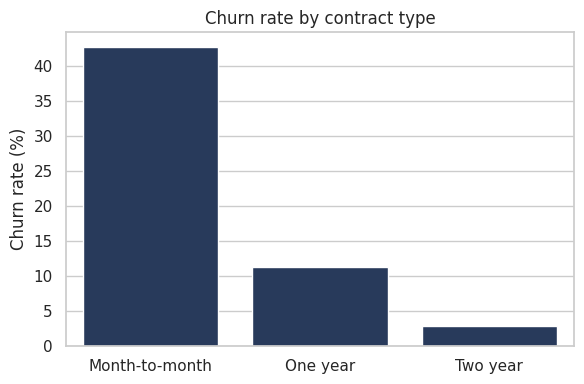

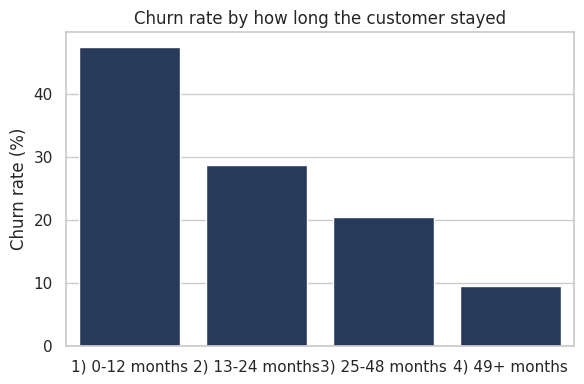

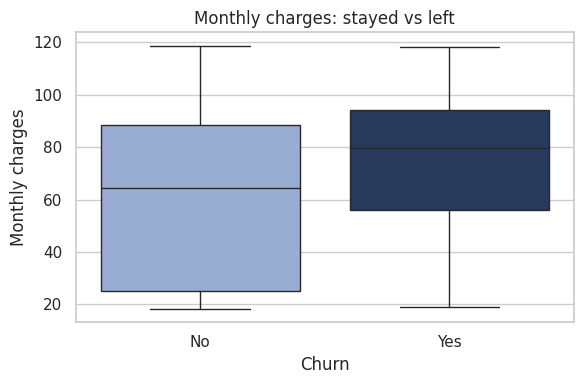

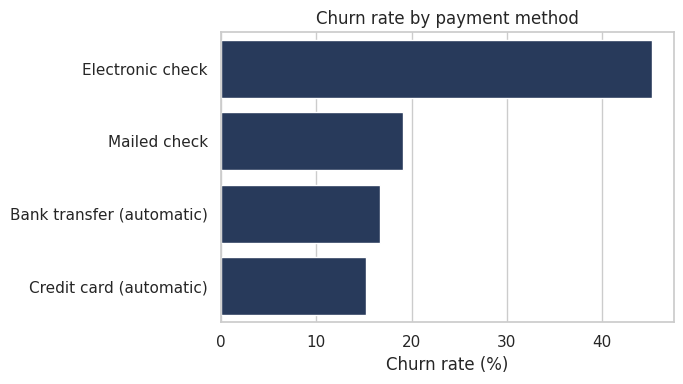

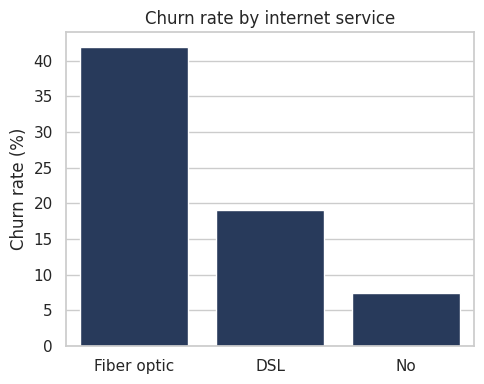

In [5]:
def save(fig_name):
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, fig_name), dpi=150)
    plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(data=sql_results["churn_by_contract"], x="Contract", y="churn_rate_pct", color="#1F3864")
plt.title("Churn rate by contract type"); plt.ylabel("Churn rate (%)"); plt.xlabel("")
save("01_churn_by_contract.png")

plt.figure(figsize=(6, 4))
sns.barplot(data=sql_results["churn_by_tenure_group"], x="tenure_group", y="churn_rate_pct", color="#1F3864")
plt.title("Churn rate by how long the customer stayed"); plt.ylabel("Churn rate (%)"); plt.xlabel("")
save("02_churn_by_tenure.png")

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#8FAADC", "#1F3864"])
plt.title("Monthly charges: stayed vs left"); plt.ylabel("Monthly charges")
save("03_monthly_charges_vs_churn.png")

plt.figure(figsize=(7, 4))
sns.barplot(data=sql_results["churn_by_payment_method"], y="PaymentMethod", x="churn_rate_pct", color="#1F3864")
plt.title("Churn rate by payment method"); plt.xlabel("Churn rate (%)"); plt.ylabel("")
save("04_churn_by_payment.png")

plt.figure(figsize=(5, 4))
sns.barplot(data=sql_results["churn_by_internet_service"], x="InternetService", y="churn_rate_pct", color="#1F3864")
plt.title("Churn rate by internet service"); plt.ylabel("Churn rate (%)"); plt.xlabel("")
save("05_churn_by_internet.png")

### STEP 5 - Models

## Prediction models



Trained on 5,634 customers, tested on 1,409 unseen customers.

| Model               |   Accuracy |   Precision |   Recall |    F1 |   ROC-AUC |
|:--------------------|-----------:|------------:|---------:|------:|----------:|
| Logistic Regression |      0.738 |       0.504 |    0.783 | 0.614 |     0.842 |
| Random Forest       |      0.774 |       0.556 |    0.749 | 0.638 |     0.844 |



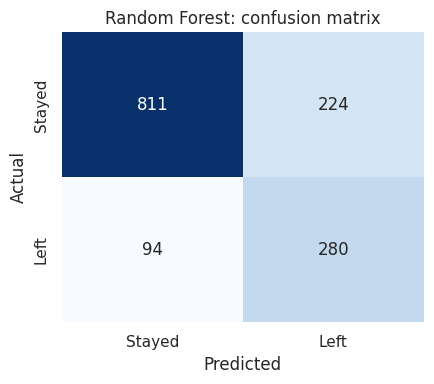

Best model by ROC-AUC: **Random Forest**



In [6]:
say("## Prediction models\n")
X = df.drop(columns=["customerID", "Churn", "Churn_flag"])
y = df["Churn_flag"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
category_cols = [c for c in X.columns if c not in numeric_cols]
prep = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), category_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE),
}
rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = (pipe, pred)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
    })
results = pd.DataFrame(rows)
results.to_csv(os.path.join(OUT, "model_results.csv"), index=False)
say(f"Trained on {len(X_train):,} customers, tested on {len(X_test):,} unseen customers.\n")
say(results.to_markdown(index=False))
say()

best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best_pipe, best_pred = fitted[best_name]
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
plt.title(f"{best_name}: confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
save("06_confusion_matrix.png")
say(f"Best model by ROC-AUC: **{best_name}**\n")

### STEP 6 - Top drivers (from Logistic Regression)

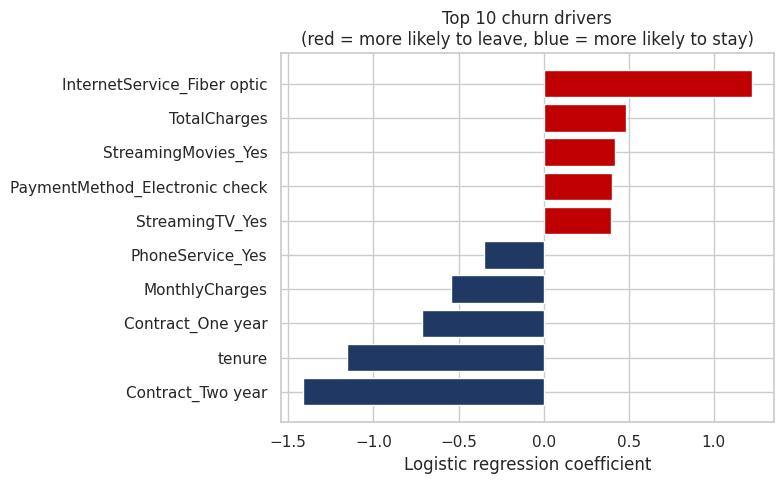

## Top 10 churn drivers (Logistic Regression)

Odds ratio above 1 = more likely to leave. Below 1 = more likely to stay.

| feature                        |   coefficient |   odds_ratio |
|:-------------------------------|--------------:|-------------:|
| Contract_Two year              |        -1.413 |        0.244 |
| InternetService_Fiber optic    |         1.222 |        3.395 |
| tenure                         |        -1.156 |        0.315 |
| Contract_One year              |        -0.715 |        0.489 |
| MonthlyCharges                 |        -0.546 |        0.579 |
| TotalCharges                   |         0.487 |        1.627 |
| StreamingMovies_Yes            |         0.421 |        1.523 |
| PaymentMethod_Electronic check |         0.402 |        1.496 |
| StreamingTV_Yes                |         0.395 |        1.485 |
| PhoneService_Yes               |        -0.348 |        0.706 |



In [7]:
lr_pipe = fitted["Logistic Regression"][0]
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = lr_pipe.named_steps["model"].coef_[0]
drivers = pd.DataFrame({"feature": [n.split("__", 1)[1] for n in names],
                        "coefficient": coefs,
                        "odds_ratio": np.exp(coefs)})
drivers["abs"] = drivers["coefficient"].abs()
top = drivers.sort_values("abs", ascending=False).head(10).drop(columns="abs").round(3)
top.to_csv(os.path.join(OUT, "top_churn_drivers.csv"), index=False)

plt.figure(figsize=(8, 5))
plot = top.sort_values("coefficient")
plt.barh(plot["feature"], plot["coefficient"],
         color=["#C00000" if c > 0 else "#1F3864" for c in plot["coefficient"]])
plt.title("Top 10 churn drivers\n(red = more likely to leave, blue = more likely to stay)")
plt.xlabel("Logistic regression coefficient")
save("07_top_drivers.png")

say("## Top 10 churn drivers (Logistic Regression)\n")
say("Odds ratio above 1 = more likely to leave. Below 1 = more likely to stay.\n")
say(top.to_markdown(index=False))
say()

### STEP 7 - Save summary

In [8]:
with open(os.path.join(OUT, "summary.md"), "w") as f:
    f.write("\n".join(summary))
print("\nDONE! Open the 'outputs' folder to see your charts and summary.md")


DONE! Open the 'outputs' folder to see your charts and summary.md
